In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

from google.colab import files

# Upload the ZIP file
uploaded = files.upload()

# Find uploaded ZIP file
zip_name = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_name is None:
    raise ValueError("Please upload the dataset ZIP file.")

# Create dataset folder
os.makedirs("dataset", exist_ok=True)

# Extract required CSV files
with zipfile.ZipFile(zip_name, "r") as zip_ref:

    required_files = [
        "diabetic_data.csv",
        "IDS_mapping.csv"
    ]

    for file_name in required_files:
        if file_name not in zip_ref.namelist():
            raise FileNotFoundError(f"{file_name} not found in ZIP")

        with zip_ref.open(file_name) as source:
            with open(os.path.join("dataset", file_name), "wb") as target:
                target.write(source.read())

print("Dataset extracted successfully!")


Saving diabetes+130-us+hospitals+for+years+1999-2008.zip to diabetes+130-us+hospitals+for+years+1999-2008.zip
Dataset extracted successfully!


In [ ]:
# Load patient records
df = pd.read_csv(
    "dataset/diabetic_data.csv",
    low_memory=False
)

# Load ID mapping information
mapping = pd.read_csv(
    "dataset/IDS_mapping.csv",
    low_memory=False
)

print("Both datasets loaded successfully!")

print("Patient Dataset Shape:", df.shape)
print("Mapping Dataset Shape:", mapping.shape)


Both datasets loaded successfully!
Patient Dataset Shape: (101766, 50)
Mapping Dataset Shape: (67, 2)


In [ ]:

# Display first five records
print("FIRST FIVE RECORDS")
display(df.head())

# Display last five records
print("LAST FIVE RECORDS")
display(df.tail())

# Display all column names
print("COLUMN NAMES")
print(df.columns.tolist())

# Dataset information
print("\nDATASET INFORMATION")
df.info()


FIRST FIVE RECORDS


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


LAST FIVE RECORDS


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,...,No,No,No,No,No,No,No,No,No,NO


COLUMN NAMES
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Nu

In [ ]:

# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

# Check unique patients
print("Unique Patients:", df["patient_nbr"].nunique())

# Check missing values
# Treat '?' as a missing value for analysis
df_check = df.replace("?", np.nan)

missing = pd.DataFrame({
    "Missing Values": df_check.isna().sum(),
    "Missing Percentage": (
        df_check.isna().mean() * 100
    ).round(2)
})

missing = missing.sort_values(
    by="Missing Percentage",
    ascending=False
)

print("\nMISSING VALUE ANALYSIS")
display(missing.head(15))


Duplicate Rows: 0
Unique Patients: 71518

MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
patient_nbr,0,0.00


READMISSION DISTRIBUTION


,count
readmitted,
NO,54864
>30,35545
<30,11357



READMISSION PERCENTAGES


,proportion
readmitted,
NO,53.91
>30,34.93
<30,11.16


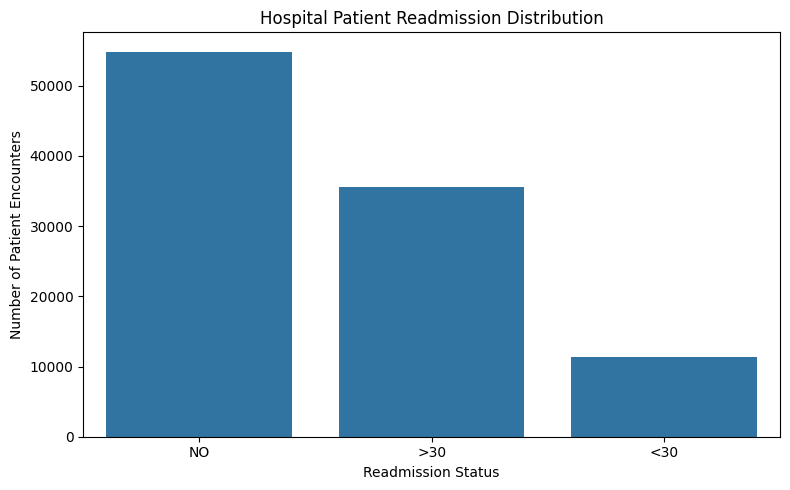

In [ ]:

# Readmission category counts
print("READMISSION DISTRIBUTION")

readmission_counts = df["readmitted"].value_counts()

display(readmission_counts)

# Readmission percentages
print("\nREADMISSION PERCENTAGES")

display(
    (df["readmitted"].value_counts(normalize=True) * 100).round(2)
)

# Visualize distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="readmitted",
    order=["NO", ">30", "<30"]
)

plt.title("Hospital Patient Readmission Distribution")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Patient Encounters")

plt.tight_layout()
plt.show()


PATIENT ENCOUNTER ANALYSIS

Total Unique Patients: 71518
Patients with Multiple Encounters: 16773
Patients with Only One Encounter: 54745
Maximum Encounters by One Patient: 40


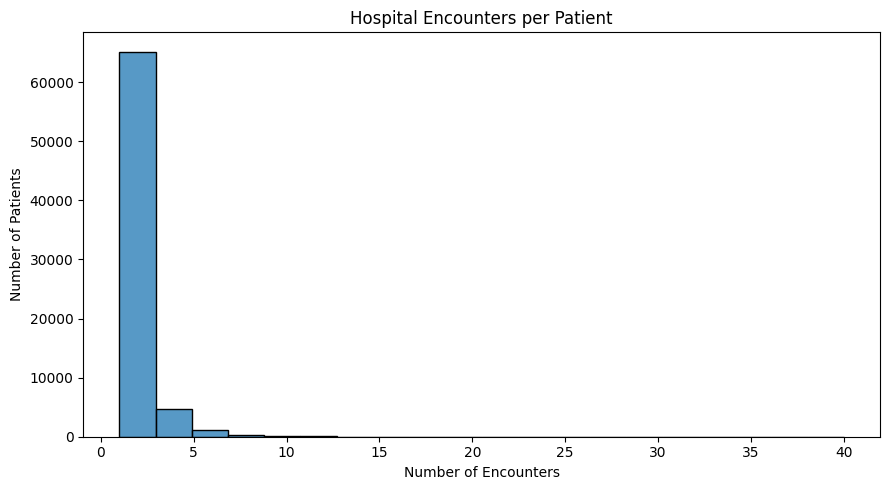

In [ ]:
# PATIENT ENCOUNTER ANALYSIS

patient_visits = df.groupby("patient_nbr")[
    "encounter_id"
].count()

print("PATIENT ENCOUNTER ANALYSIS")

print("\nTotal Unique Patients:", len(patient_visits))

print(
    "Patients with Multiple Encounters:",
    (patient_visits > 1).sum()
)

print(
    "Patients with Only One Encounter:",
    (patient_visits == 1).sum()
)

print(
    "Maximum Encounters by One Patient:",
    patient_visits.max()
)

# Visualization
plt.figure(figsize=(9, 5))

sns.histplot(
    patient_visits,
    bins=20
)

plt.title("Hospital Encounters per Patient")
plt.xlabel("Number of Encounters")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()


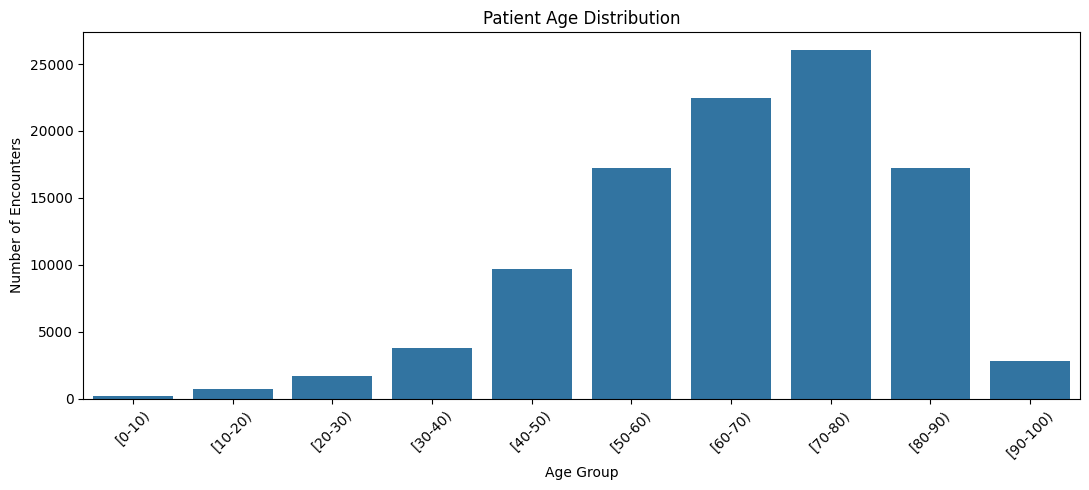

AGE GROUP PERCENTAGES


,proportion
age,
[0-10),0.16
[10-20),0.68
[20-30),1.63
[30-40),3.71
[40-50),9.52
[50-60),16.96
[60-70),22.09
[70-80),25.62
[80-90),16.90


In [ ]:

# AGE DISTRIBUTION ANALYSIS

age_order = [
    "[0-10)", "[10-20)", "[20-30)",
    "[30-40)", "[40-50)", "[50-60)",
    "[60-70)", "[70-80)", "[80-90)",
    "[90-100)"
]

plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="age",
    order=age_order
)

plt.title("Patient Age Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Encounters")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Age group percentages
age_percentage = (
    df["age"].value_counts(normalize=True) * 100
).reindex(age_order)

print("AGE GROUP PERCENTAGES")
display(age_percentage.round(2))


READMISSION PERCENTAGE BY AGE


readmitted,<30,>30,NO
age,,,
[0-10),1.86,16.15,81.99
[10-20),5.79,32.42,61.79
[20-30),14.24,30.78,54.98
[30-40),11.23,31.44,57.32
[40-50),10.60,33.85,55.55
[50-60),9.67,34.29,56.04
[60-70),11.13,35.12,53.75
[70-80),11.77,36.35,51.88
[80-90),12.08,36.19,51.73


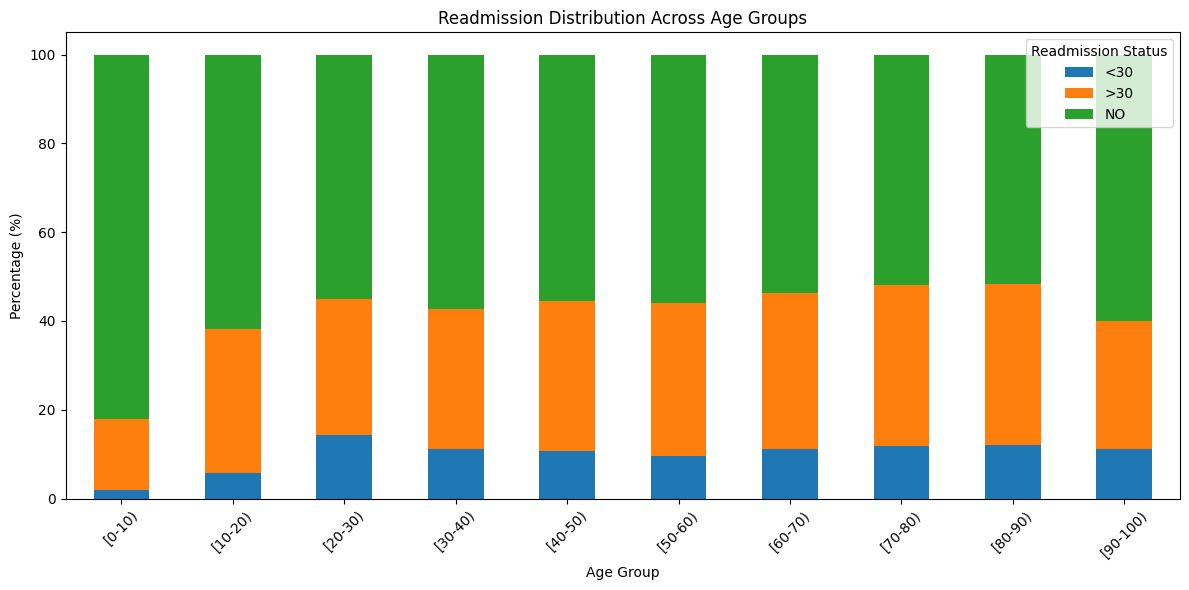

In [ ]:

# READMISSION BY AGE

age_readmission = pd.crosstab(
    df["age"],
    df["readmitted"],
    normalize="index"
) * 100

age_readmission = age_readmission.reindex(age_order)

print("READMISSION PERCENTAGE BY AGE")
display(age_readmission.round(2))

# Visualization
age_readmission.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Readmission Distribution Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Percentage (%)")

plt.legend(title="Readmission Status")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


GENDER DISTRIBUTION


,count
gender,
Female,54708
Male,47055
Unknown/Invalid,3



READMISSION BY GENDER (%)


readmitted,<30,>30,NO
gender,,,
Female,11.25,35.68,53.08
Male,11.06,34.06,54.88
Unknown/Invalid,0.00,0.00,100.00


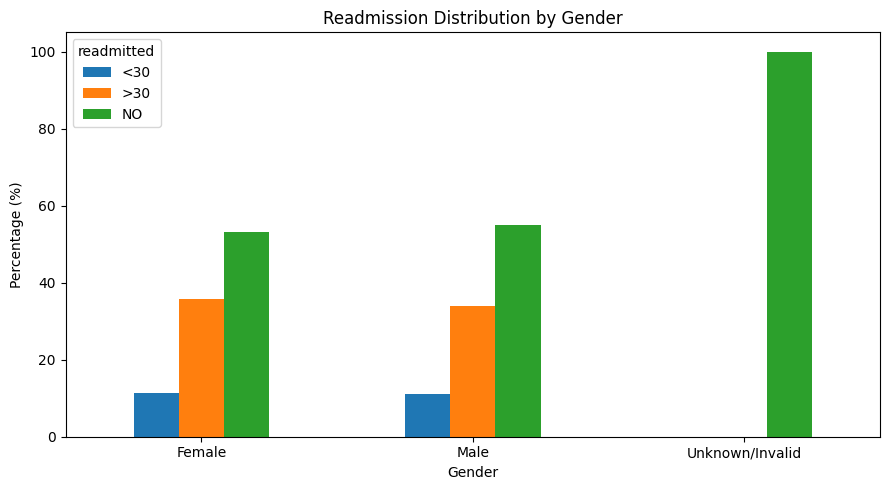

In [ ]:

# GENDER ANALYSIS

gender_counts = df["gender"].value_counts()

print("GENDER DISTRIBUTION")
display(gender_counts)

gender_readmission = pd.crosstab(
    df["gender"],
    df["readmitted"],
    normalize="index"
) * 100

print("\nREADMISSION BY GENDER (%)")
display(gender_readmission.round(2))

# Visualization
gender_readmission.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Readmission Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [17]:
# ADMISSION TYPE ANALYSIS

# Find the end of admission type section
discharge_start = mapping[
    mapping.iloc[:, 0].astype(str).str.strip()
    == "discharge_disposition_id"
].index

if len(discharge_start) == 0:
    raise ValueError("Discharge section not found. Check mapping CSV.")

# Extract admission type records
admission_section = mapping.loc[:discharge_start[0] - 1].copy()

admission_section.columns = ["admission_type_id", "description"]

admission_section = admission_section.dropna()

admission_section["admission_type_id"] = pd.to_numeric(
    admission_section["admission_type_id"],
    errors="coerce"
)

admission_section = admission_section.dropna(
    subset=["admission_type_id"]
)

admission_section["admission_type_id"] = (
    admission_section["admission_type_id"].astype(int)
)

print("ADMISSION TYPE MAPPING:")
display(admission_section)

# Readmission analysis
admission_map = dict(zip(
    admission_section["admission_type_id"],
    admission_section["description"]
))
admission_map[6] = "Unknown / NULL"
admission_labels = df["admission_type_id"].map(
    admission_map
).fillna("Unknown / Not mapped")

print("\nADMISSION TYPE DISTRIBUTION:")
display(admission_labels.value_counts())

print("\nREADMISSION BY ADMISSION TYPE (%):")

admission_analysis = pd.crosstab(
    admission_labels,
    df["readmitted"],
    normalize="index"
) * 100

display(admission_analysis.round(2))

ADMISSION TYPE MAPPING:


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
6,7,Trauma Center
7,8,Not Mapped



ADMISSION TYPE DISTRIBUTION:


,count
admission_type_id,
Emergency,53990
Elective,18869
Urgent,18480
Unknown / NULL,5291
Not Available,4785
Not Mapped,320
Trauma Center,21
Newborn,10



READMISSION BY ADMISSION TYPE (%):


readmitted,<30,>30,NO
admission_type_id,,,
Elective,10.39,30.45,59.16
Emergency,11.52,35.76,52.71
Newborn,10.00,20.00,70.00
Not Available,10.34,35.97,53.69
Not Mapped,8.44,26.25,65.31
Trauma Center,0.00,0.00,100.00
Unknown / NULL,11.08,42.17,46.76
Urgent,11.18,34.91,53.91


DISCHARGE DISPOSITION MAPPING:


,discharge_disposition_id,description
10,1.0,Discharged to home
11,2.0,Discharged/transferred to another short term h...
12,3.0,Discharged/transferred to SNF
13,4.0,Discharged/transferred to ICF
14,5.0,Discharged/transferred to another type of inpa...
15,6.0,Discharged/transferred to home with home healt...
16,7.0,Left AMA
17,8.0,Discharged/transferred to home under care of H...
18,9.0,Admitted as an inpatient to this hospital
19,10.0,Neonate discharged to another hospital for neo...



DISCHARGE DISPOSITION DISTRIBUTION


,count
discharge_disposition_id,
Discharged to home,60234
Discharged/transferred to SNF,13954
Discharged/transferred to home with home health service,12902
Unknown / Not mapped,3691
Discharged/transferred to another short term hospital,2128
Discharged/transferred to another rehab fac including rehab units of a hospital .,1993
Expired,1642
Discharged/transferred to another type of inpatient care institution,1184
Not Mapped,989



READMISSION BY DISCHARGE DISPOSITION (%)


readmitted,<30,>30,NO
discharge_disposition_id,,,
Admitted as an inpatient to this hospital,42.86,9.52,47.62
Discharged to home,9.30,35.72,54.98
Discharged/transferred to ICF,12.76,34.11,53.13
Discharged/transferred to SNF,14.66,35.23,50.11
Discharged/transferred to a federal health care facility.,0.00,20.00,80.00
Discharged/transferred to a long term care hospital.,7.28,34.95,57.77
Discharged/transferred to a nursing facility certified under Medicaid but not certified under Medicare.,14.58,33.33,52.08
Discharged/transferred to another rehab fac including rehab units of a hospital .,27.70,26.04,46.26
Discharged/transferred to another short term hospital,16.07,31.39,52.54


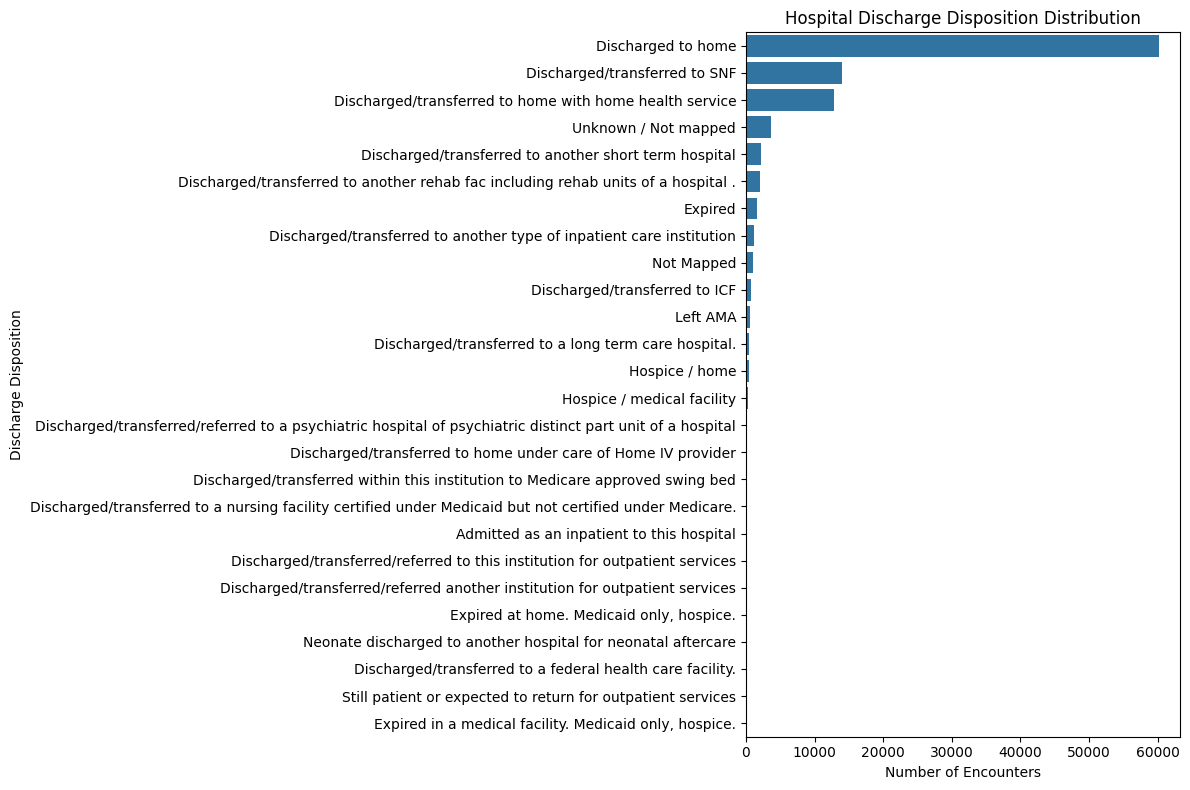

In [ ]:
# DISCHARGE DISPOSITION ANALYSIS

# Find discharge disposition section
discharge_start = mapping[
    mapping.iloc[:, 0].astype(str).str.strip()
    == "discharge_disposition_id"
].index[0]

# Find next section
source_start = mapping[
    mapping.iloc[:, 0].astype(str).str.strip()
    == "admission_source_id"
].index[0]

# Extract only discharge disposition mapping
discharge_section = mapping.loc[
    discharge_start + 1:source_start - 1
].iloc[:, :2].copy()

discharge_section.columns = [
    "discharge_disposition_id",
    "description"
]

# Convert ID into numeric values
discharge_section["discharge_disposition_id"] = pd.to_numeric(
    discharge_section["discharge_disposition_id"],
    errors="coerce"
)

# Remove empty rows
discharge_section = discharge_section.dropna(
    subset=["discharge_disposition_id", "description"]
)

# Create mapping dictionary
discharge_map = dict(zip(
    discharge_section["discharge_disposition_id"].astype(int),
    discharge_section["description"].str.strip()
))

print("DISCHARGE DISPOSITION MAPPING:")
display(discharge_section)

# Map discharge IDs
discharge_labels = df["discharge_disposition_id"].map(
    discharge_map
).fillna("Unknown / Not mapped")

# Distribution
print("\nDISCHARGE DISPOSITION DISTRIBUTION")

discharge_counts = discharge_labels.value_counts()
display(discharge_counts)

# Readmission analysis
discharge_analysis = pd.crosstab(
    discharge_labels,
    df["readmitted"],
    normalize="index"
) * 100

print("\nREADMISSION BY DISCHARGE DISPOSITION (%)")
display(discharge_analysis.round(2))

# Visualization
plt.figure(figsize=(12, 8))

sns.countplot(
    y=discharge_labels,
    order=discharge_counts.index
)

plt.title("Hospital Discharge Disposition Distribution")
plt.xlabel("Number of Encounters")
plt.ylabel("Discharge Disposition")

plt.tight_layout()
plt.show()

ADMISSION SOURCE MAPPING:


,admission_source_id,description
42,1,Physician Referral
43,2,Clinic Referral
44,3,HMO Referral
45,4,Transfer from a hospital
46,5,Transfer from a Skilled Nursing Facility (SNF)
47,6,Transfer from another health care facility
48,7,Emergency Room
49,8,Court/Law Enforcement
50,9,Not Available
51,10,Transfer from critial access hospital



ADMISSION SOURCE DISTRIBUTION


,count
admission_source_id,
Emergency Room,57494
Physician Referral,29565
Unknown / Not mapped,6781
Transfer from a hospital,3187
Transfer from another health care facility,2264
Clinic Referral,1104
Transfer from a Skilled Nursing Facility (SNF),855
HMO Referral,187
Not Mapped,161



READMISSION BY ADMISSION SOURCE (%)


readmitted,<30,>30,NO
admission_source_id,,,
Clinic Referral,10.05,28.08,61.87
Court/Law Enforcement,12.50,25.00,62.50
Emergency Room,11.69,37.69,50.63
Extramural Birth,0.00,0.00,100.00
HMO Referral,15.51,31.02,53.48
Normal Delivery,0.00,0.00,100.00
Not Available,10.40,12.80,76.80
Not Mapped,13.66,50.31,36.02
Physician Referral,10.59,32.61,56.81


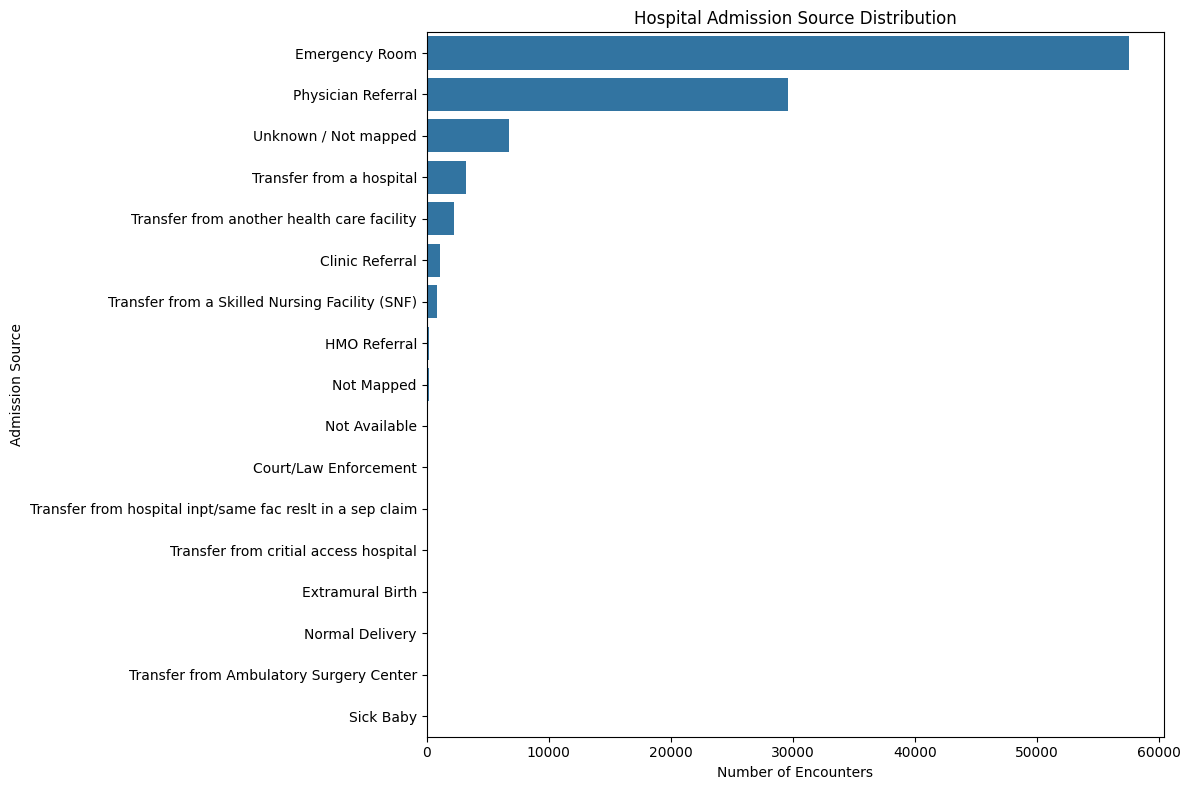

In [ ]:
# ADMISSION SOURCE ANALYSIS

# Find admission source section
source_start = mapping[
    mapping.iloc[:, 0].astype(str).str.strip()
    == "admission_source_id"
].index[0]

# Extract admission source mapping
source_section = mapping.loc[
    source_start + 1:, :
].iloc[:, :2].copy()

source_section.columns = [
    "admission_source_id",
    "description"
]

# Convert ID into numeric values
source_section["admission_source_id"] = pd.to_numeric(
    source_section["admission_source_id"],
    errors="coerce"
)

# Remove empty rows
source_section = source_section.dropna(
    subset=["admission_source_id", "description"]
)

# Create mapping dictionary
source_map = dict(zip(
    source_section["admission_source_id"].astype(int),
    source_section["description"].str.strip()
))

print("ADMISSION SOURCE MAPPING:")
display(source_section)

# Map admission source IDs
source_labels = df["admission_source_id"].map(
    source_map
).fillna("Unknown / Not mapped")

# Admission source distribution
print("\nADMISSION SOURCE DISTRIBUTION")

source_counts = source_labels.value_counts()
display(source_counts)

# Readmission analysis
source_analysis = pd.crosstab(
    source_labels,
    df["readmitted"],
    normalize="index"
) * 100

print("\nREADMISSION BY ADMISSION SOURCE (%)")
display(source_analysis.round(2))

# Visualization
plt.figure(figsize=(12, 8))

sns.countplot(
    y=source_labels,
    order=source_counts.index
)

plt.title("Hospital Admission Source Distribution")
plt.xlabel("Number of Encounters")
plt.ylabel("Admission Source")

plt.tight_layout()
plt.show()

READMISSION BY TIME IN HOSPITAL (%)


readmitted,<30,>30,NO
time_in_hospital,,,
1,8.18,31.47,60.35
2,9.94,34.36,55.70
3,10.67,34.27,55.06
4,11.81,36.37,51.82
5,12.03,35.98,51.99
6,12.59,36.54,50.87
7,12.83,36.23,50.93
8,14.23,36.19,49.58
9,13.72,36.61,49.67



AVERAGE HOSPITAL STAY BY READMISSION


,time_in_hospital
readmitted,
<30,4.77
>30,4.50
NO,4.25


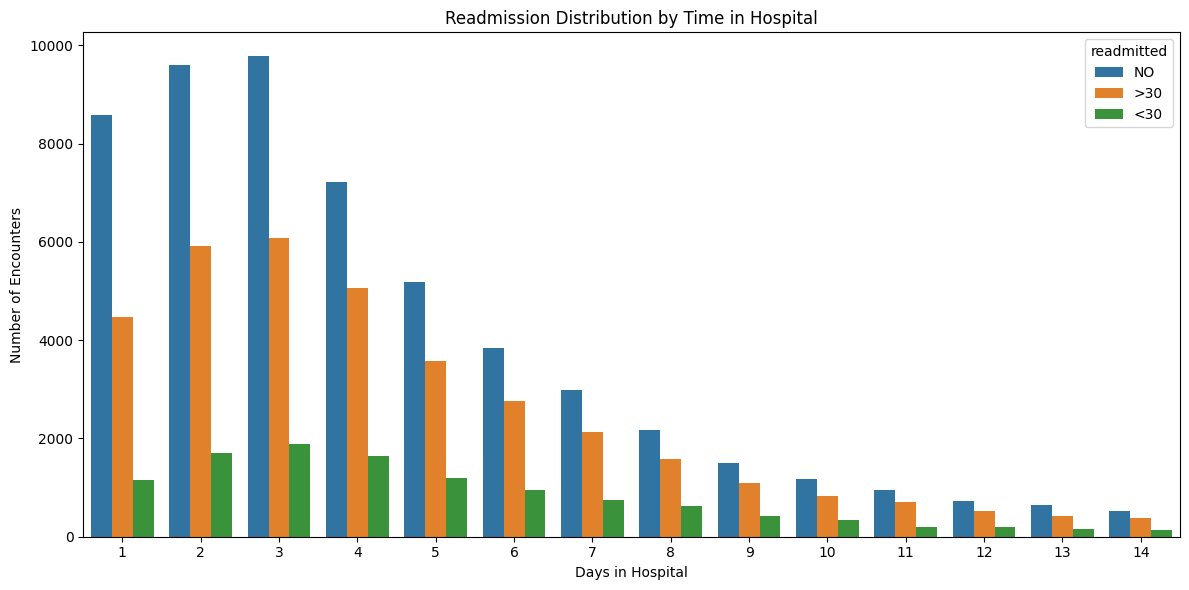

In [ ]:
# READMISSION ANALYSIS BY TIME IN HOSPITAL

# Readmission distribution by hospital stay duration
stay_analysis = pd.crosstab(
    df["time_in_hospital"],
    df["readmitted"],
    normalize="index"
) * 100

print("READMISSION BY TIME IN HOSPITAL (%)")
display(stay_analysis.round(2))

# Average hospital stay by readmission category
print("\nAVERAGE HOSPITAL STAY BY READMISSION")
display(
    df.groupby("readmitted")["time_in_hospital"]
    .mean()
    .round(2)
)

# Visualization
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="time_in_hospital",
    hue="readmitted"
)

plt.title("Readmission Distribution by Time in Hospital")
plt.xlabel("Days in Hospital")
plt.ylabel("Number of Encounters")

plt.tight_layout()
plt.show()

PREVIOUS HOSPITAL VISITS SUMMARY:


,number_outpatient,number_emergency,number_inpatient
count,101766.00,101766.00,101766.00
mean,0.37,0.20,0.64
std,1.27,0.93,1.26
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.00,0.00,0.00
75%,0.00,0.00,1.00
max,42.00,76.00,21.00



READMISSION BY NUMBER_OUTPATIENT (%)


readmitted,<30,>30,NO
number_outpatient,,,
0,10.67,32.98,56.35
1,13.92,43.45,42.62
2,13.75,46.36,39.90
3,12.29,45.15,42.56
4,15.10,43.68,41.22
5,11.82,45.59,42.59
6,13.20,50.83,35.97
7,15.48,53.55,30.97
8,5.10,40.82,54.08



READMISSION BY NUMBER_EMERGENCY (%)


readmitted,<30,>30,NO
number_emergency,,,
0,10.47,33.42,56.11
1,14.35,44.94,40.71
2,18.27,48.82,32.91
3,20.28,51.59,28.14
4,30.75,50.80,18.45
5,24.48,55.73,19.79
6,23.40,60.64,15.96
7,26.03,64.38,9.59
8,32.00,50.00,18.00



READMISSION BY NUMBER_INPATIENT (%)


readmitted,<30,>30,NO
number_inpatient,,,
0,8.44,30.06,61.51
1,12.92,41.84,45.24
2,17.43,47.50,35.06
3,20.29,49.43,30.28
4,23.61,50.62,25.77
5,31.40,48.65,19.95
6,34.58,49.58,15.83
7,35.45,45.52,19.03
8,44.37,46.36,9.27


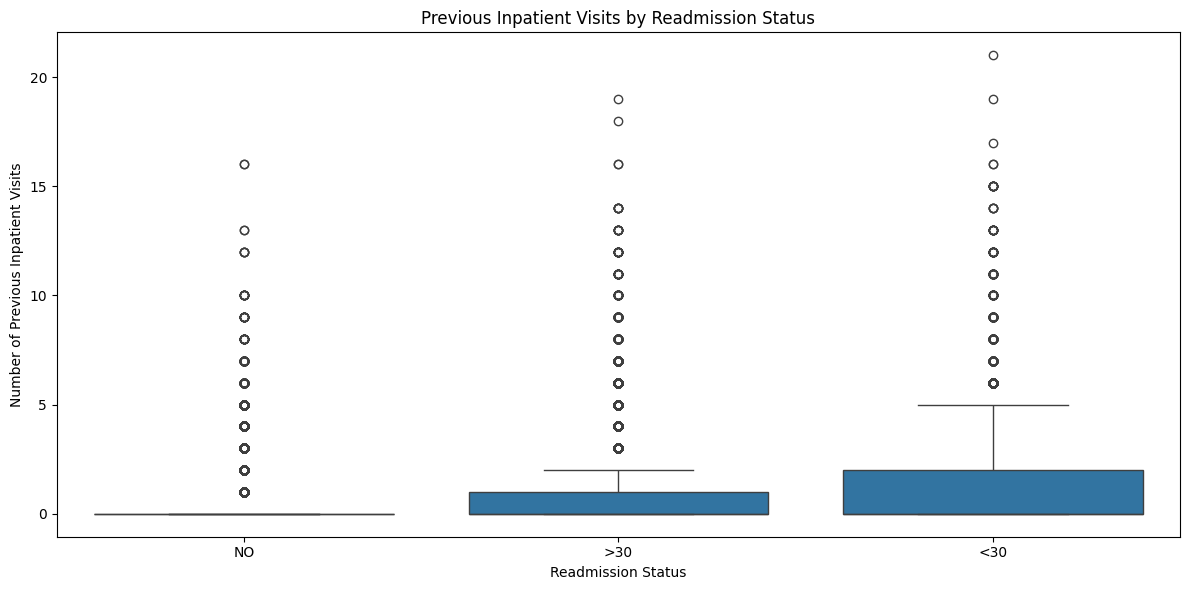

In [ ]:
# PREVIOUS HOSPITAL VISITS ANALYSIS

visit_columns = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

# Summary statistics
print("PREVIOUS HOSPITAL VISITS SUMMARY:")
display(df[visit_columns].describe().round(2))

# Readmission analysis
for col in visit_columns:
    print(f"\nREADMISSION BY {col.upper()} (%)")

    analysis = pd.crosstab(
        df[col],
        df["readmitted"],
        normalize="index"
    ) * 100

    display(analysis.round(2))

# Visualization
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="readmitted",
    y="number_inpatient"
)

plt.title("Previous Inpatient Visits by Readmission Status")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Previous Inpatient Visits")

plt.tight_layout()
plt.show()

MEDICATION CHANGE DISTRIBUTION:


,count
change,
No,54755
Ch,47011



DIABETES MEDICATION DISTRIBUTION:


,count
diabetesMed,
Yes,78363
No,23403



READMISSION BY MEDICATION CHANGE (%):


readmitted,<30,>30,NO
change,,,
Ch,11.82,36.74,51.44
No,10.59,33.37,56.04



READMISSION BY DIABETES MEDICATION (%):


readmitted,<30,>30,NO
diabetesMed,,,
No,9.60,30.88,59.52
Yes,11.63,36.14,52.24


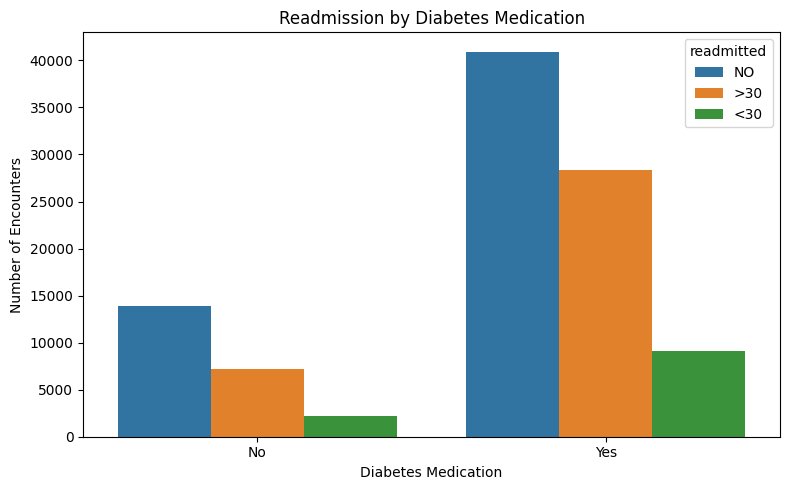

In [ ]:
# MEDICATION ANALYSIS

medication_columns = [
    "metformin", "repaglinide", "nateglinide",
    "chlorpropamide", "glimepiride", "glipizide",
    "glyburide", "pioglitazone", "rosiglitazone",
    "acarbose", "miglitol", "troglitazone",
    "tolazamide", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone"
]

# Medication change distribution
print("MEDICATION CHANGE DISTRIBUTION:")
display(df["change"].value_counts())

print("\nDIABETES MEDICATION DISTRIBUTION:")
display(df["diabetesMed"].value_counts())

# Readmission by medication change
print("\nREADMISSION BY MEDICATION CHANGE (%):")

medication_analysis = pd.crosstab(
    df["change"],
    df["readmitted"],
    normalize="index"
) * 100

display(medication_analysis.round(2))

# Readmission by diabetes medication
print("\nREADMISSION BY DIABETES MEDICATION (%):")

diabetes_analysis = pd.crosstab(
    df["diabetesMed"],
    df["readmitted"],
    normalize="index"
) * 100

display(diabetes_analysis.round(2))

# Visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="diabetesMed",
    hue="readmitted"
)

plt.title("Readmission by Diabetes Medication")
plt.xlabel("Diabetes Medication")
plt.ylabel("Number of Encounters")

plt.tight_layout()
plt.show()


DIAG_1 DISTRIBUTION:


,count
diag_1,
428,6862
414,6581
786,4016
410,3614
486,3508
427,2766
491,2275
715,2151
682,2042



DIAG_2 DISTRIBUTION:


,count
diag_2,
276,6752
428,6662
250,6071
427,5036
401,3736
496,3305
599,3288
403,2823
414,2650



DIAG_3 DISTRIBUTION:


,count
diag_3,
250,11555
401,8289
276,5175
428,4577
427,3955
414,3664
496,2605
403,2357
585,1992



READMISSION BY PRIMARY DIAGNOSIS (%)


readmitted,<30,>30,NO,total
diag_1,,,,
428,14.11,45.02,40.88,6862
414,9.04,32.29,58.67,6581
786,7.25,35.31,57.45,4016
410,10.32,29.47,60.21,3614
486,8.95,39.03,52.02,3508
427,9.11,35.21,55.68,2766
491,12.62,47.16,40.22,2275
715,10.00,26.41,63.60,2151
682,8.96,37.90,53.13,2042


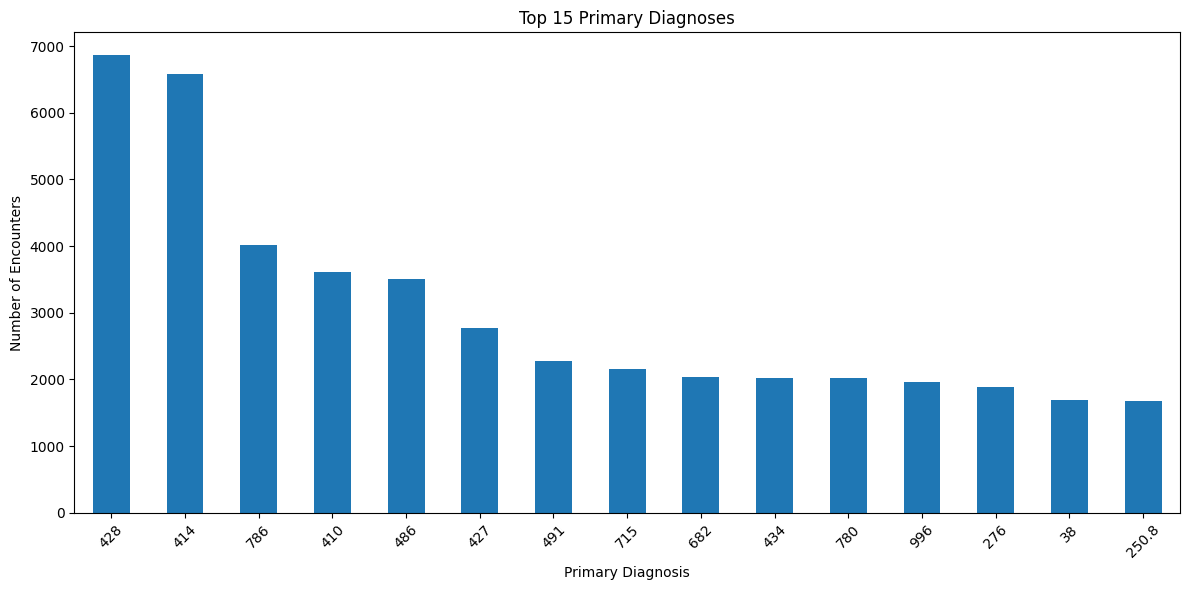

In [ ]:
# DIAGNOSIS ANALYSIS

diagnosis_columns = ["diag_1", "diag_2", "diag_3"]

# Diagnosis distribution
for col in diagnosis_columns:
    print(f"\n{col.upper()} DISTRIBUTION:")
    display(df[col].value_counts().head(15))

# Readmission analysis by primary diagnosis
print("\nREADMISSION BY PRIMARY DIAGNOSIS (%)")

diagnosis_analysis = pd.crosstab(
    df["diag_1"],
    df["readmitted"],
    normalize="index"
) * 100

display(
    diagnosis_analysis.round(2)
    .assign(total=df["diag_1"].value_counts())
    .sort_values("total", ascending=False)
    .head(15)
)

# Visualization
plt.figure(figsize=(12, 6))

df["diag_1"].value_counts().head(15).plot(kind="bar")

plt.title("Top 15 Primary Diagnoses")
plt.xlabel("Primary Diagnosis")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# LAB TEST ANALYSIS

lab_columns = ["max_glu_serum", "A1Cresult"]

for col in lab_columns:
    print(f"\n{col.upper()} DISTRIBUTION:")
    display(df[col].value_counts())

    print(f"\nREADMISSION BY {col.upper()} (%)")
    analysis = pd.crosstab(
        df[col],
        df["readmitted"],
        normalize="index"
    ) * 100

    display(analysis.round(2))


MAX_GLU_SERUM DISTRIBUTION:


,count
max_glu_serum,
Norm,2597
>200,1485
>300,1264



READMISSION BY MAX_GLU_SERUM (%)


readmitted,<30,>30,NO
max_glu_serum,,,
>200,12.46,35.69,51.85
>300,14.32,41.22,44.46
Norm,11.36,34.08,54.56



A1CRESULT DISTRIBUTION:


,count
A1Cresult,
>8,8216
Norm,4990
>7,3812



READMISSION BY A1CRESULT (%)


readmitted,<30,>30,NO
A1Cresult,,,
>7,10.05,34.10,55.85
>8,9.87,35.31,54.82
Norm,9.66,32.04,58.30


In [ ]:
# ADDITIONAL FEATURE ANALYSIS

feature_columns = [
    "race",
    "gender",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

for col in feature_columns:
    print(f"\nREADMISSION BY {col.upper()} (%)")

    analysis = pd.crosstab(
        df[col],
        df["readmitted"],
        normalize="index"
    ) * 100

    display(analysis.round(2))


READMISSION BY RACE (%)


readmitted,<30,>30,NO
race,,,
?,8.27,23.67,68.06
AfricanAmerican,11.22,34.53,54.25
Asian,10.14,25.12,64.74
Caucasian,11.29,35.64,53.07
Hispanic,10.41,31.52,58.08
Other,9.63,29.61,60.76



READMISSION BY GENDER (%)


readmitted,<30,>30,NO
gender,,,
Female,11.25,35.68,53.08
Male,11.06,34.06,54.88
Unknown/Invalid,0.00,0.00,100.00



READMISSION BY ADMISSION_TYPE_ID (%)


readmitted,<30,>30,NO
admission_type_id,,,
1,11.52,35.76,52.71
2,11.18,34.91,53.91
3,10.39,30.45,59.16
4,10.00,20.00,70.00
5,10.34,35.97,53.69
6,11.08,42.17,46.76
7,0.00,0.00,100.00
8,8.44,26.25,65.31



READMISSION BY DISCHARGE_DISPOSITION_ID (%)


readmitted,<30,>30,NO
discharge_disposition_id,,,
1,9.30,35.72,54.98
2,16.07,31.39,52.54
3,14.66,35.23,50.11
4,12.76,34.11,53.13
5,20.86,29.56,49.58
6,12.70,41.56,45.74
7,14.45,35.47,50.08
8,13.89,35.19,50.93
9,42.86,9.52,47.62



READMISSION BY ADMISSION_SOURCE_ID (%)


readmitted,<30,>30,NO
admission_source_id,,,
1,10.59,32.61,56.81
2,10.05,28.08,61.87
3,15.51,31.02,53.48
4,9.70,21.09,69.22
5,11.81,27.60,60.58
6,9.36,17.58,73.06
7,11.69,37.69,50.63
8,12.50,25.00,62.50
9,10.40,12.80,76.80


In [ ]:
# EDA SUMMARY

print("DATASET SUMMARY")
print("Total Encounters:", df.shape[0])
print("Total Patients:", df["patient_nbr"].nunique())
print("Total Features:", df.shape[1])

print("\nREADMISSION DISTRIBUTION")
display(df["readmitted"].value_counts())

print("\nKEY FINDINGS")

print("1. 30-Day Readmission Rate:",
      round((df["readmitted"] == "<30").mean() * 100, 2), "%")

print("2. Average Hospital Stay:",
      round(df["time_in_hospital"].mean(), 2), "days")

print("3. Average Previous Inpatient Visits:",
      round(df["number_inpatient"].mean(), 2))

print("4. Most Common Age Group:",
      df["age"].value_counts().idxmax())

print("5. Most Common Primary Diagnosis:",
      df["diag_1"].value_counts().idxmax())

DATASET SUMMARY
Total Encounters: 101766
Total Patients: 71518
Total Features: 50

READMISSION DISTRIBUTION


,count
readmitted,
NO,54864
>30,35545
<30,11357



KEY FINDINGS
1. 30-Day Readmission Rate: 11.16 %
2. Average Hospital Stay: 4.4 days
3. Average Previous Inpatient Visits: 0.64
4. Most Common Age Group: [70-80)
5. Most Common Primary Diagnosis: 428


In [ ]:
# DATA PREPROCESSING

# Create binary target
df["target"] = (df["readmitted"] == "<30").astype(int)

# Replace missing values
df = df.replace("?", np.nan)

# Remove unnecessary columns
drop_columns = [
    "encounter_id",
    "patient_nbr",
    "readmitted",
    "weight",
    "payer_code",
    "medical_specialty"
]

df = df.drop(columns=drop_columns)

# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Fill missing categorical values
for col in X.select_dtypes(include="object").columns:
    X[col] = X[col].fillna("Unknown")

# Fill missing numerical values
for col in X.select_dtypes(include=np.number).columns:
    X[col] = X[col].fillna(X[col].median())

print("Preprocessing Completed")
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nTarget Distribution:")
display(y.value_counts())

Preprocessing Completed
Features Shape: (101766, 44)
Target Shape: (101766,)

Target Distribution:


,count
target,
0,90409
1,11357


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identify categorical and numerical columns
categorical_columns = X.select_dtypes(include="object").columns
numerical_columns = X.select_dtypes(include=np.number).columns

# Preprocessing
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ("num", StandardScaler(), numerical_columns)
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Logistic Regression model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train model
model.fit(X_train, y_train)

print("Model Training Completed")
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Model Training Completed
Training Shape: (81412, 44)
Testing Shape: (20354, 44)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predictions
y_pred = model.predict(X_test)

# Evaluation metrics
print("MODEL PERFORMANCE")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

MODEL PERFORMANCE
Accuracy: 0.644
Precision: 0.1668
Recall: 0.5482
F1 Score: 0.2557

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.92      0.66      0.77     18083
           1       0.17      0.55      0.26      2271

    accuracy                           0.64     20354
   macro avg       0.54      0.60      0.51     20354
weighted avg       0.84      0.64      0.71     20354


CONFUSION MATRIX
[[11862  6221]
 [ 1026  1245]]


In [ ]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score

# Create validation data from training data
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Train model on training portion
tuned_model = clone(model)
tuned_model.fit(X_train_new, y_train_new)

# Get validation probabilities
y_prob = tuned_model.predict_proba(X_val)[:, 1]

# Test different thresholds
for threshold in [0.5, 0.4, 0.3, 0.2, 0.1]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(
        "Threshold:", threshold,
        "| Precision:", round(precision_score(y_val, y_pred_threshold), 4),
        "| Recall:", round(recall_score(y_val, y_pred_threshold), 4),
        "| F1 Score:", round(f1_score(y_val, y_pred_threshold), 4)
    )

Threshold: 0.5 | Precision: 0.1655 | Recall: 0.5289 | F1 Score: 0.2521
Threshold: 0.4 | Precision: 0.1388 | Recall: 0.7716 | F1 Score: 0.2353
Threshold: 0.3 | Precision: 0.1212 | Recall: 0.9119 | F1 Score: 0.2139
Threshold: 0.2 | Precision: 0.1146 | Recall: 0.9785 | F1 Score: 0.2052
Threshold: 0.1 | Precision: 0.1123 | Recall: 0.9967 | F1 Score: 0.2018


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Final predictions using optimized threshold
y_test_prob = tuned_model.predict_proba(X_test)[:, 1]

y_test_pred = (y_test_prob >= 0.4).astype(int)

print("FINAL MODEL PERFORMANCE")
print("Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_test_pred), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_test_pred))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_test_pred))

FINAL MODEL PERFORMANCE
Precision: 0.1378
Recall: 0.7666
F1 Score: 0.2336

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.93      0.40      0.56     18083
           1       0.14      0.77      0.23      2271

    accuracy                           0.44     20354
   macro avg       0.53      0.58      0.40     20354
weighted avg       0.84      0.44      0.52     20354


CONFUSION MATRIX
[[ 7188 10895]
 [  530  1741]]


In [ ]:
# FEATURE IMPORTANCE FROM LOGISTIC REGRESSION

feature_names = tuned_model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = tuned_model.named_steps[
    "classifier"
].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Importance"] = feature_importance[
    "Coefficient"
].abs()

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
display(feature_importance.head(15).round(4))

TOP 15 IMPORTANT FEATURES


,Feature,Coefficient,Importance
1480,cat__diag_3_250.91,2.1080,2.1080
446,cat__diag_1_643,1.9193,1.9193
701,cat__diag_2_136,1.9046,1.9046
1760,cat__diag_3_602,1.8296,1.8296
677,cat__diag_1_999,-1.7972,1.7972
1192,cat__diag_2_807,-1.7787,1.7787
342,cat__diag_1_506,1.7637,1.7637
1399,cat__diag_3_156,1.7371,1.7371
448,cat__diag_1_646,1.7344,1.7344
688,cat__diag_1_V58,1.6981,1.6981


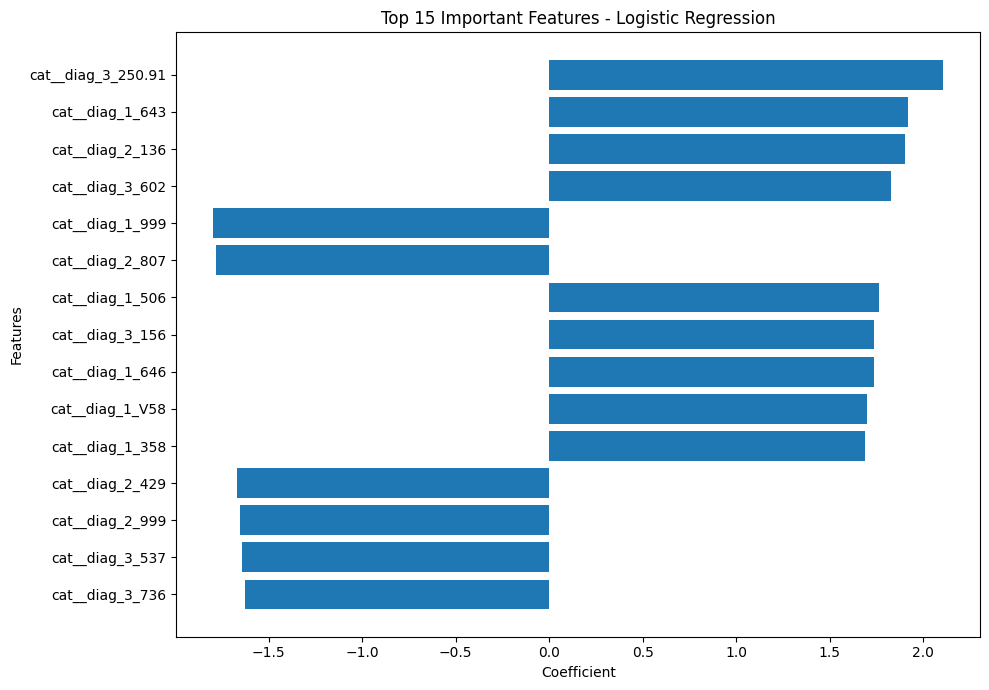

In [ ]:
# TOP 15 FEATURE IMPORTANCE PLOT

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.title("Top 15 Important Features - Logistic Regression")
plt.xlabel("Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [ ]:
# DASHBOARD DATASET EXPORT

dashboard_df = df.copy()

dashboard_df["Readmission_Status"] = dashboard_df["target"].map({
    0: "Not Readmitted",
    1: "Readmitted Within 30 Days"
})

dashboard_df.to_csv(
    "Hospital_Readmission_Dashboard.csv",
    index=False
)

print("Dashboard Dataset Exported Successfully")
print("Dataset Shape:", dashboard_df.shape)

from google.colab import files
files.download("Hospital_Readmission_Dashboard.csv")

Dashboard Dataset Exported Successfully
Dataset Shape: (101766, 46)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

target                      1.000000
number_inpatient            0.165147
number_emergency            0.060747
discharge_disposition_id    0.050560
number_diagnoses            0.049524
time_in_hospital            0.044199
num_medications             0.038432
num_lab_procedures          0.020364
number_outpatient           0.018893
admission_source_id         0.005820
admission_type_id          -0.011651
num_procedures             -0.012227
Name: target, dtype: float64


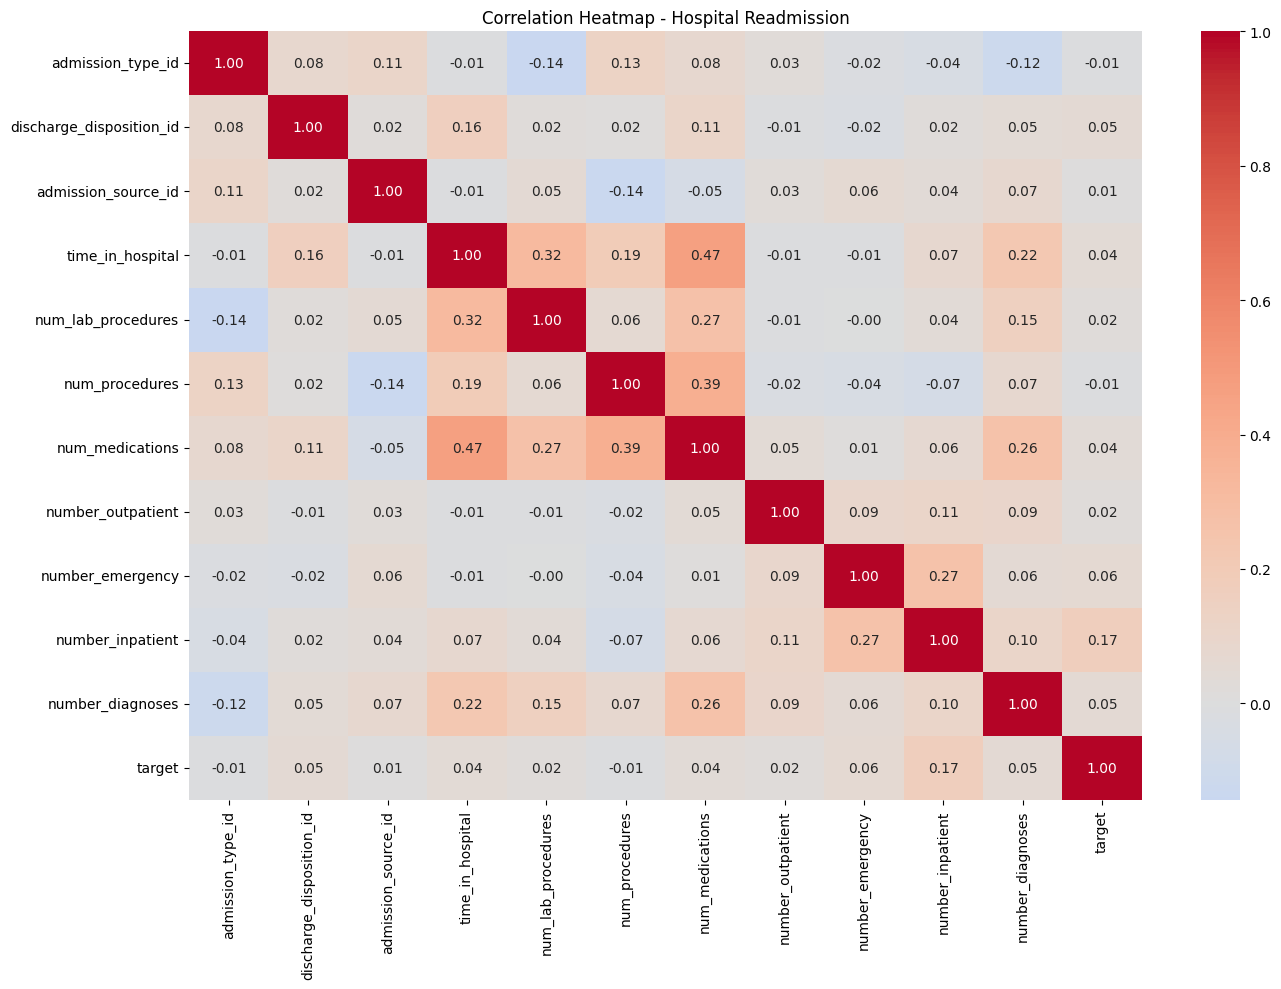

In [21]:
numeric_df = numeric_df.drop(
    columns=["encounter_id", "patient_nbr"],
    errors="ignore"
)

correlation = numeric_df.corr()

print(correlation["target"].sort_values(ascending=False))

plt.figure(figsize=(14, 10))
sns.heatmap(correlation, annot=True, cmap="coolwarm",
            center=0, fmt=".2f")
plt.title("Correlation Heatmap - Hospital Readmission")
plt.tight_layout()
plt.show()